In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("AquaGuard - Data Exploration")
print("Libraries imported successfully!")

AquaGuard - Data Exploration
Libraries imported successfully!


In [2]:
data_path = "../data/input_model_potenc_predXfault7_A.csv"

df = pd.read_csv(data_path)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 8737
Columns: 20


,timestamp,fault_d7,4700008966_kW,4700008966_power_hour,4408411600_kW,4408411600_power_hour,4608927500_kvar_hour,238045_ws_temp,279805_ws_vigor,279804_ws_level,279625_ws_temp,279623_ws_vigor,319235_ws_temp,279831_ws_temp,326417_ws_temp,326416_ws_vigor,temp_site1_anomaly_score,sfc_temp_site1_anomaly_score,gw_lvl_site2_anomaly_score,gw_temp_site2_anomaly_score
0,31-12-2021 23:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,01-01-2022 0:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.34,7.63,9.48,38.44
2,01-01-2022 1:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.96,0.87,9.48,38.44
3,01-01-2022 2:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.01,1.23,9.48,38.44
4,01-01-2022 3:00,0,0.0,0.0,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.51,4.86,9.48,38.44


In [3]:
print("Dataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 8737 entries, 0 to 8736
Data columns (total 20 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   timestamp                     8737 non-null   str    
 1   fault_d7                      8737 non-null   int64  
 2   4700008966_kW                 8737 non-null   float64
 3   4700008966_power_hour         8737 non-null   float64
 4   4408411600_kW                 6578 non-null   float64
 5   4408411600_power_hour         6578 non-null   float64
 6   4608927500_kvar_hour          8737 non-null   float64
 7   238045_ws_temp                8737 non-null   float64
 8   279805_ws_vigor               8724 non-null   float64
 9   279804_ws_level               8724 non-null   float64
 10  279625_ws_temp                8256 non-null   float64
 11  279623_ws_vigor               8256 non-null   float64
 12  319235_ws_temp                8700 non-null   float6

fault_d7
0    2305
1    6432
Name: count, dtype: int64


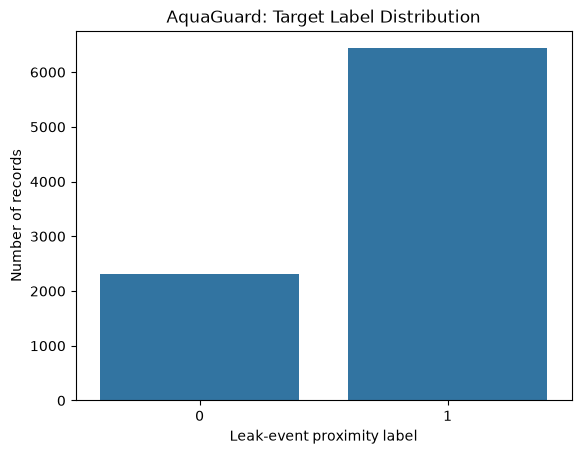

In [4]:
label_counts = df["fault_d7"].value_counts().sort_index()

print(label_counts)

sns.countplot(data=df, x="fault_d7")
plt.title("AquaGuard: Target Label Distribution")
plt.xlabel("Leak-event proximity label")
plt.ylabel("Number of records")
plt.show()

In [5]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
c:\Users\shubh\AquaGuard\.venv\Scripts\python.exe


MISSING VALUE REPORT
                              Missing_Count  Missing_Percentage
326417_ws_temp                         4267               48.84
326416_ws_vigor                        4267               48.84
4408411600_kW                          2159               24.71
4408411600_power_hour                  2159               24.71
gw_temp_site2_anomaly_score            1441               16.49
gw_lvl_site2_anomaly_score             1441               16.49
279625_ws_temp                          481                5.51
279623_ws_vigor                         481                5.51
279831_ws_temp                           43                0.49
319235_ws_temp                           37                0.42
279805_ws_vigor                          13                0.15
279804_ws_level                          13                0.15
sfc_temp_site1_anomaly_score              1                0.01
temp_site1_anomaly_score                  1                0.01


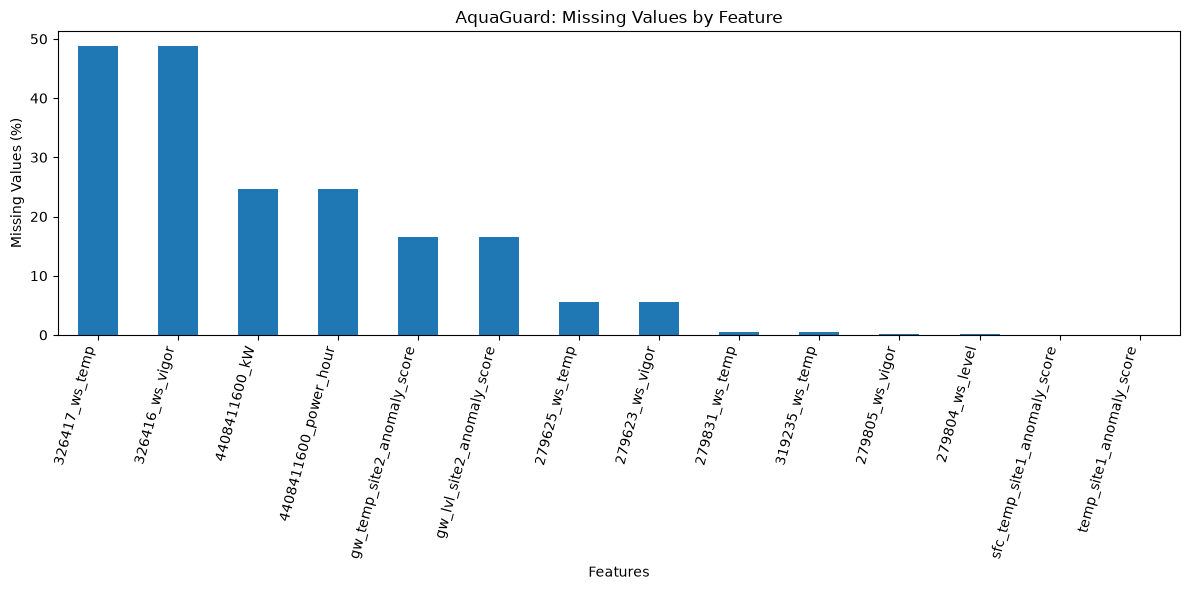

In [6]:
# Calculate missing values and their percentages
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df)) * 100
})

# Display columns with missing values, highest percentage first
missing_report = missing_report[missing_report["Missing_Count"] > 0]
missing_report = missing_report.sort_values(
    by="Missing_Percentage",
    ascending=False
)

print("MISSING VALUE REPORT")
print(missing_report.round(2))

# Visualize missing values
plt.figure(figsize=(12, 6))
missing_report["Missing_Percentage"].plot(kind="bar")
plt.title("AquaGuard: Missing Values by Feature")
plt.xlabel("Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [7]:
# Convert timestamp strings into datetime values
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    dayfirst=True,
    errors="coerce"
)

# Check for invalid timestamps
print("Invalid timestamps:", df["timestamp"].isna().sum())

# Check the date range
print("\nFirst timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

# Check whether timestamps are in chronological order
print(
    "\nTimestamps already sorted:",
    df["timestamp"].is_monotonic_increasing
)

# Check for repeated timestamps
print(
    "Duplicate timestamps:",
    df["timestamp"].duplicated().sum()
)

# Display the first five timestamps
print("\nFirst five timestamps:")
print(df["timestamp"].head())

Invalid timestamps: 0

First timestamp: 2021-12-31 23:00:00
Last timestamp: 2022-12-30 23:00:00

Timestamps already sorted: False
Duplicate timestamps: 0

First five timestamps:
0   2021-12-31 23:00:00
1   2022-01-01 00:00:00
2   2022-01-01 01:00:00
3   2022-01-01 02:00:00
4   2022-01-01 03:00:00
Name: timestamp, dtype: datetime64[us]


In [8]:
# Find rows where the timestamp is earlier than the previous row
out_of_order = df.loc[
    df["timestamp"].diff().lt(pd.Timedelta(0)),
    ["timestamp", "fault_d7"]
]

print("Number of out-of-order records:", len(out_of_order))
print("\nFirst 10 out-of-order records:")
print(out_of_order.head(10))

# Display the timestamps around the first ordering problem
if not out_of_order.empty:
    first_bad_index = out_of_order.index[0]

    print("\nNearby records:")
    print(
        df.loc[
            max(0, first_bad_index - 2):first_bad_index + 2,
            ["timestamp", "fault_d7"]
        ]
    )

Number of out-of-order records: 22

First 10 out-of-order records:
      timestamp  fault_d7
289  2022-01-13         1
745  2022-01-02         1
1033 2022-02-13         1
1417 2022-01-03         1
1705 2022-03-13         1
2161 2022-01-04         0
2449 2022-04-13         1
2881 2022-01-05         0
3169 2022-05-13         0
3625 2022-01-06         1

Nearby records:
              timestamp  fault_d7
287 2022-12-01 22:00:00         1
288 2022-12-01 23:00:00         1
289 2022-01-13 00:00:00         1
290 2022-01-13 01:00:00         1
291 2022-01-13 02:00:00         1


# Read the original timestamp strings directly from the CSV
raw_df = pd.read_csv("../data/input_model_potenc_predXfault7_A.csv")

print("First 15 original timestamps:")
print(raw_df["timestamp"].head(15).to_string(index=True))

print("\nTimestamps around the first ordering problem:")
print(raw_df["timestamp"].iloc[285:295].to_string(index=True))

print("\nLast 10 original timestamps:")
print(raw_df["timestamp"].tail(10).to_string(index=True))

In [9]:
# Read the original CSV without changing the existing dataframe
raw_df = pd.read_csv("../data/input_model_potenc_predXfault7_A.csv")

print("FIRST 15 ORIGINAL TIMESTAMPS")
print(raw_df["timestamp"].head(15).to_string())

print("\nTIMESTAMPS AROUND ROW 289")
print(raw_df["timestamp"].iloc[285:295].to_string())

print("\nLAST 10 ORIGINAL TIMESTAMPS")
print(raw_df["timestamp"].tail(10).to_string())

FIRST 15 ORIGINAL TIMESTAMPS
0     31-12-2021 23:00
1      01-01-2022 0:00
2      01-01-2022 1:00
3      01-01-2022 2:00
4      01-01-2022 3:00
5      01-01-2022 4:00
6      01-01-2022 5:00
7      01-01-2022 6:00
8      01-01-2022 7:00
9      01-01-2022 8:00
10     01-01-2022 9:00
11    01-01-2022 10:00
12    01-01-2022 11:00
13    01-01-2022 12:00
14    01-01-2022 13:00

TIMESTAMPS AROUND ROW 289
285    01-12-2022 20:00
286    01-12-2022 21:00
287    01-12-2022 22:00
288    01-12-2022 23:00
289     13-01-2022 0:00
290     13-01-2022 1:00
291     13-01-2022 2:00
292     13-01-2022 3:00
293     13-01-2022 4:00
294     13-01-2022 5:00

LAST 10 ORIGINAL TIMESTAMPS
8727    30-12-2022 14:00
8728    30-12-2022 15:00
8729    30-12-2022 16:00
8730    30-12-2022 17:00
8731    30-12-2022 18:00
8732    30-12-2022 19:00
8733    30-12-2022 20:00
8734    30-12-2022 21:00
8735    30-12-2022 22:00
8736    30-12-2022 23:00
